# CS-781 Capstone, Phase 1, Attempt 2: Encoder-Decoder Legal Language Model (from scratch)

Architecture #2 of the required four. Attempt 1 was a decoder-only transformer. This notebook is a **T5-style encoder-decoder**.

| | Attempt 1 (decoder-only) | Attempt 2 (this notebook) |
|---|---|---|
| Stacks | one causal stack | bidirectional **encoder** (6 layers) + causal **decoder** (6 layers) with **cross-attention** |
| Reading the prompt | causal (left-to-right) | encoder reads the whole 512-word prompt bidirectionally |
| Objective | next-token on every position | **prefix -> continuation** (75%) + **span corruption** (25%) |
| Embeddings | tied in/out | one table shared by encoder, decoder and output head (tied) |
| Generation state | growing KV-cache | encoder runs once; decoder KV-cache + cached cross-attention K/V |
| Same as attempt 1 | data cleaning, corpus, BPE tokenizer, packing, validation split, training loop, checkpoints, `prediction.json` / `submission.zip` | |

Why this architecture: the task is "read 512 words, write 128", which is exactly the encoder-decoder shape.
The encoder transfers to Phases 2-5 and 7 (NER, rhetorical roles, judgment, statutes, retrieval) and the full model is a ready seq2seq model for Phase 6 (summarisation).

Pipeline: **stream and clean -> train BPE -> pack tokens -> train ~124M encoder-decoder -> tune decoding locally (BERTScore) -> prediction.json -> submission.zip**

## 1. Configuration

In [1]:
import os, sys, json, re, math, time, zlib, hashlib, random, zipfile, heapq, subprocess, shutil
from collections import Counter, defaultdict
from dataclasses import dataclass
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint

DEBUG = False            # True = tiny end-to-end smoke test (minutes, not hours)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
OUTPUT_DIR = "/kaggle/working/cs781_phase1_encdec"      # checkpoints, predictions, submission
# To skip re-building the corpus / tokenizer / packed bins, point REUSE_DIR at the attempt-1 output
# folder (it must contain train_*.jsonl, val.jsonl, bpe_merges.json, train.bin, val.bin, corpus_stats.json),
# e.g. a Kaggle dataset: REUSE_DIR = "/kaggle/input/<your-dataset>/cs781_phase1"
REUSE_DIR = None
DATA_DIR = REUSE_DIR or OUTPUT_DIR
os.makedirs(OUTPUT_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)
PREDICTION_PATH = f"{OUTPUT_DIR}/prediction.json"
SUBMISSION_ZIP = f"{OUTPUT_DIR}/submission.zip"

# --- Data plan: IDENTICAL to attempt 1 (file, keep-probability, word budget, min words per document) ---
SOURCES = {
    "supreme_court": ("train_supreme_court.json", 0.50, 66_000_000, 200),
    "high_courts":   ("train_high_courts.json",   0.05, 27_000_000, 200),
    "tribunals":     ("train_tribunals.json",     0.15,  8_000_000, 200),
    "acts":          ("train_acts.json",          1.00,  9_000_000,  50),
}
MAX_WORDS_PER_DOC = 8_000
VAL_MOD = 100

# --- Tokenizer: IDENTICAL to attempt 1 ---
VOCAB_SIZE = 32_000
TOKENIZER_CHARS_PER_SOURCE = 40_000_000
TOKENIZER_MIN_WORD_FREQ = 3

# --- Encoder-decoder model (about 124M parameters at these settings) ---
D_MODEL, N_HEAD, N_FFN = 768, 12, 2048
N_ENC_LAYER, N_DEC_LAYER = 6, 6
N_SENTINEL = 100                 # extra ids <extra_0>.. used only by span corruption (not in the BPE)
GRAD_CKPT = False                # True trades ~30% speed for much lower memory

# --- Packing / batch geometry ---
# train.bin is cut into BLOCK-token blocks. A block is split at a random point e:
#   encoder input = block[:e]   decoder target = block[e:]     (prefix -> continuation)
BLOCK = 1280
ENC_MIN, ENC_MAX = 512, 1024     # e is drawn per micro-batch; test prompts are ~700-900 tokens
VAL_ENC, VAL_DEC = 800, 256      # fixed validation split: 800-token prompt -> 256-token continuation
# T5-style span corruption on the remaining 25% of micro-batches
SPAN_FRAC, NOISE_DENSITY, MEAN_SPAN = 0.25, 0.15, 3.0
SPAN_ENC_LEN = 1024              # encoder length of span-corruption batches

# --- Optimisation ---
MICRO_BS, GRAD_ACCUM = 4, 16     # 4*16*1280 = ~82k tokens per optimizer step (same as attempt 1)
LR, MIN_LR, WEIGHT_DECAY, WARMUP_FRAC = 5e-4, 5e-5, 0.1, 0.03
EVAL_EVERY, EVAL_BATCHES, LOG_EVERY = 200, 60, 20
MAX_TRAIN_HOURS = 10.0

# --- Generation ---
PROMPT_WORDS, TARGET_WORDS = 512, 128
MAX_NEW_TOKENS = 256
EOS_PLACEHOLDER = "<|endoftext|>"
USE_BERTSCORE = True             # primary competition metric; falls back to ROUGE-L if unavailable

if DEBUG:
    SOURCES = {k: (v[0], 1.0, 300_000, v[3]) for k, v in SOURCES.items()}
    VOCAB_SIZE, TOKENIZER_CHARS_PER_SOURCE, TOKENIZER_MIN_WORD_FREQ = 4_000, 2_000_000, 2
    D_MODEL, N_HEAD, N_FFN, N_ENC_LAYER, N_DEC_LAYER = 128, 4, 352, 2, 2
    BLOCK, ENC_MIN, ENC_MAX, VAL_ENC, VAL_DEC, SPAN_ENC_LEN = 256, 96, 192, 128, 64, 160
    EVAL_EVERY, EVAL_BATCHES, LOG_EVERY, MICRO_BS, GRAD_ACCUM = 20, 5, 5, 8, 2
    MAX_NEW_TOKENS = 64
    VAL_MOD = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "")

device: cuda | Tesla T4


## 2. Access the dataset and inspect the test prompts
(unchanged from attempt 1)

In [2]:
from huggingface_hub import HfApi, hf_hub_download, login

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("capstone-phase1-token")
    os.environ["HF_TOKEN"] = HF_TOKEN
    login(token=HF_TOKEN)
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

_repo_files = HfApi().list_repo_files(HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN)

def fetch(*must_contain):
    """Find a repo file whose path contains all given substrings (case-insensitive)."""
    hits = [f for f in _repo_files if all(s.lower() in f.lower() for s in must_contain)]
    if not hits:
        raise FileNotFoundError(f"{must_contain} not found. Repo has: {_repo_files[:40]}")
    return hf_hub_download(HF_DATASET_REPO, hits[0], repo_type="dataset", token=HF_TOKEN)

test_path = fetch("phase_1", "test", ".json")
with open(test_path, encoding="utf-8") as f:
    test_data = json.load(f)
test_prompts_raw = [v["text"] for v in test_data.values()]
frac_nl = np.mean(["\n" in p for p in test_prompts_raw])
KEEP_NEWLINES = bool(frac_nl > 0.5)
print(f"test prompts: {len(test_prompts_raw)} | with newlines: {frac_nl:.0%} "
      f"| median words: {np.median([len(p.split()) for p in test_prompts_raw]):.0f}")
print("KEEP_NEWLINES =", KEEP_NEWLINES, "(training text is formatted to match the test prompts)")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

test prompts: 1000 | with newlines: 0% | median words: 512
KEEP_NEWLINES = False (training text is formatted to match the test prompts)


In [3]:
test_prompts_raw[1]

'Instead of taking cognizance of the offence, he has, in the exercise of his discretion, sent the complaint for investigation by police under Section 156." 12) In Tula Ram & Ors. vs. Kishore Singh (supra) again this Court considered order for investigation under [Section 2] 156 (3) on a complaint. After considering various earlier decisions, the Court on a careful consideration of the facts and circumstances of the case propounded the following legal propositions:- ".... 1. That a Magistrate can order investigation under [S. 156 (3)] only at the pre-cognizance stage, that is to say, before taking cognizance under Sections 190, 200 and 204 and where a Magistrate decides to take cognizance under the provisions of Chapter 14 he is not entitled in law to order any investigation under Section 156 (3) though in cases not falling within the proviso to Section 202 he can order an investigation by the police which would be in the nature of an enquiry as contemplated by Sec. 202 of the Code. 2. 

## 3. Cleaning rules for Indian legal text
(unchanged from attempt 1: same cleaning, same normalisation applied to train text and test prompts)

In [4]:
BOILERPLATE = [
    re.compile(r"^\s*page\s+\d+(\s+of\s+\d+)?\s*$", re.I),
    re.compile(r"^\s*-?\s*\d{1,4}\s*-?\s*$"),                          # bare page numbers
    re.compile(r"^\s*(https?://|www\.)\S+\s*$", re.I),
    re.compile(r"^\s*(indian\s*kanoon|manupatra|scc\s*online|supreme\s*court\s*cases)\b.*$", re.I),
    re.compile(r"^\s*(digitally\s+signed\s+by|signature\s+not\s+verified|reason:|location:)\b.*$", re.I),
    re.compile(r"^\s*(reportable|non-?reportable)\s*$", re.I),
]
CHAR_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-",
    "\u2212": "-", "\u2026": "...", "\u00a0": " ", "\u200b": "", "\ufeff": "", "\u00ad": "",
})
CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")

def normalize_text(t: str, keep_newlines: bool) -> str:
    """Character and whitespace normalisation. Applied to train text AND test prompts."""
    t = CTRL.sub(" ", t.translate(CHAR_MAP))
    if keep_newlines:
        t = re.sub(r"[ \t]+", " ", t)
        t = re.sub(r" ?\n ?", "\n", t)
        t = re.sub(r"\n{3,}", "\n\n", t)
    else:
        t = re.sub(r"\s+", " ", t)
    return t.strip()

def clean_document(t: str, keep_newlines: bool) -> str:
    kept = [l for l in t.splitlines() if not any(p.match(l) for p in BOILERPLATE)]
    return normalize_text("\n".join(kept), keep_newlines)

def passes_quality(text: str, min_words: int):
    """Returns (ok, reason)."""
    if len(text.split()) < min_words:
        return False, "too_short"
    sample = text[:20_000]
    n = max(len(sample), 1)
    if sum(c.isalpha() for c in sample) / n < 0.60:
        return False, "low_alpha"             # OCR garbage, number tables
    if sum(ord(c) < 128 for c in sample) / n < 0.90:
        return False, "non_english"
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if len(lines) > 20 and len(set(lines)) / len(lines) < 0.30:
        return False, "repetitive"
    return True, ""

def stream_records(path):
    """Stream a (possibly multi-GB) JSON array without loading it into RAM."""
    try:
        import ijson
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ijson"], check=False)
        import ijson
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec

## 4. Stage A: stream, clean, deduplicate, split by document
(unchanged from attempt 1; skipped automatically if the corpus already exists in `DATA_DIR`)

In [5]:
def build_corpus():
    seen, all_stats = set(), {}
    val_f = open(f"{DATA_DIR}/val.jsonl", "w", encoding="utf-8")
    for src, (fname, keep_p, budget, min_words) in SOURCES.items():
        path = fetch(fname)
        out = open(f"{DATA_DIR}/train_{src}.jsonl", "w", encoding="utf-8")
        rng = random.Random(SEED)
        st = Counter(); words_kept = 0; t0 = time.time()
        for rec in stream_records(path):
            st["seen"] += 1
            if rng.random() > keep_p:
                continue
            text = clean_document(rec["text"] if isinstance(rec, dict) else str(rec), KEEP_NEWLINES)
            ok, why = passes_quality(text, min_words)
            if not ok:
                st["drop_" + why] += 1; continue
            fp = hashlib.md5(re.sub(r"\W+", "", text[:3000].lower()).encode()).hexdigest()
            if fp in seen:
                st["drop_duplicate"] += 1; continue
            seen.add(fp)
            words = text.split()
            if len(words) > MAX_WORDS_PER_DOC:
                text = " ".join(words[:MAX_WORDS_PER_DOC]); st["truncated"] += 1
                words = words[:MAX_WORDS_PER_DOC]
            row = json.dumps({"src": src, "text": text}, ensure_ascii=False) + "\n"
            if zlib.crc32(fp.encode()) % VAL_MOD == 0:
                val_f.write(row); st["val_docs"] += 1
            else:
                out.write(row); st["train_docs"] += 1
            words_kept += len(words)
            if words_kept >= budget:
                break
        out.close()
        st["words"] = words_kept; st["minutes"] = round((time.time() - t0) / 60, 1)
        all_stats[src] = dict(st)
        flag = "" if words_kept >= 0.95 * budget else "  <-- UNDER BUDGET: raise keep-probability"
        print(f"{src:14s} {dict(st)}{flag}")
    val_f.close()
    json.dump(all_stats, open(f"{DATA_DIR}/corpus_stats.json", "w"), indent=2)

if not os.path.exists(f"{DATA_DIR}/val.jsonl"):
    build_corpus()
else:
    print("corpus already built:", open(f"{DATA_DIR}/corpus_stats.json").read()[:600])

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 8.3 MB/s eta 0:00:00
supreme_court  {'seen': 43063, 'train_docs': 20705, 'truncated': 2033, 'val_docs': 235, 'drop_too_short': 616, 'drop_low_alpha': 13, 'drop_duplicate': 23, 'drop_non_english': 1, 'words': 66003826, 'minutes': 1.8}


Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

high_courts    {'seen': 1079597, 'drop_too_short': 19671, 'train_docs': 32707, 'val_docs': 344, 'truncated': 262, 'drop_low_alpha': 256, 'drop_duplicate': 898, 'words': 27000462, 'minutes': 1.2}


... (2 outputs left out)

tribunals      {'seen': 31934, 'train_docs': 4506, 'truncated': 157, 'drop_too_short': 270, 'val_docs': 41, 'drop_low_alpha': 3, 'words': 8000161, 'minutes': 0.2}


Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

acts           {'seen': 2622, 'train_docs': 2577, 'truncated': 467, 'val_docs': 29, 'drop_low_alpha': 12, 'drop_too_short': 1, 'drop_duplicate': 3, 'words': 9001700, 'minutes': 0.3}


## 5. Byte-level BPE tokenizer, implemented from scratch
(unchanged from attempt 1; the saved merges are reused if present in `DATA_DIR`)

In [6]:
PRETOKEN_RE = re.compile(r"""'(?:[sdmt]|ll|ve|re)| ?[^\W\d_]+| ?\d{1,3}| ?(?:[^\s\w]|_)+|\s+(?!\S)|\s+""")

class ByteBPE:
    def __init__(self, merges=None):
        self.merges = [tuple(m) for m in (merges or [])]
        self.rank = {p: i for i, p in enumerate(self.merges)}
        self.vocab = [bytes([i]) for i in range(256)]
        for a, b in self.merges:
            self.vocab.append(self.vocab[a] + self.vocab[b])
        self.eos_id = len(self.vocab)
        self.vocab.append(EOS_PLACEHOLDER.encode())
        self.vocab_size = len(self.vocab)
        self._cache = {}

    # ---------- training ----------
    @staticmethod
    def train(chunk_counts, vocab_size, min_freq=3, log_every=2000):
        n_merges = vocab_size - 256 - 1                      # last id is EOS
        items = [(c.encode("utf-8"), f) for c, f in chunk_counts.items() if f >= min_freq]
        words = [list(b) for b, _ in items]
        freqs = [f for _, f in items]
        pair_cnt, where = defaultdict(int), defaultdict(set)
        for i, w in enumerate(words):
            for p in zip(w, w[1:]):
                pair_cnt[p] += freqs[i]; where[p].add(i)
        heap = [(-c, p) for p, c in pair_cnt.items()]
        heapq.heapify(heap)
        merges, t0 = [], time.time()
        while len(merges) < n_merges:
            best = None
            while heap:                                       # lazy deletion
                negc, p = heapq.heappop(heap)
                c = pair_cnt.get(p, 0)
                if c <= 0: continue
                if c != -negc:
                    heapq.heappush(heap, (-c, p)); continue
                best = p; break
            if best is None: break
            a, b = best; new_id = 256 + len(merges); merges.append(best)
            changed = set()
            for i in list(where[best]):
                w, f = words[i], freqs[i]
                out, j, n, hit = [], 0, len(w), False
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2; hit = True
                    else:
                        out.append(w[j]); j += 1
                if not hit: continue
                for q in zip(w, w[1:]): pair_cnt[q] -= f
                for q in zip(out, out[1:]):
                    pair_cnt[q] += f; where[q].add(i); changed.add(q)
                words[i] = out
            where.pop(best, None); pair_cnt.pop(best, None)
            for q in changed:
                if pair_cnt[q] > 0: heapq.heappush(heap, (-pair_cnt[q], q))
            if len(merges) % log_every == 0:
                print(f"  merges {len(merges):6d}/{n_merges} | {time.time() - t0:5.0f}s")
        return ByteBPE(merges)

    # ---------- encoding / decoding ----------
    def _encode_chunk(self, chunk):
        hit = self._cache.get(chunk)
        if hit is not None: return hit
        ids = list(chunk.encode("utf-8"))
        while len(ids) > 1:
            best_r, best_p = None, None
            for p in zip(ids, ids[1:]):
                r = self.rank.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best_r, best_p = r, p
            if best_p is None: break
            a, b = best_p; new_id = 256 + best_r; out, j = [], 0
            while j < len(ids):
                if j < len(ids) - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(new_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        if len(self._cache) > 3_000_000: self._cache.clear()
        self._cache[chunk] = ids
        return ids

    def encode(self, text):
        ids = []
        for chunk in PRETOKEN_RE.findall(text):
            ids.extend(self._encode_chunk(chunk))
        return ids

    def decode(self, ids):
        data = b"".join(self.vocab[i] for i in ids if i != self.eos_id)
        return data.decode("utf-8", errors="replace")

    def save(self, path):
        json.dump({"merges": self.merges, "eos": EOS_PLACEHOLDER}, open(path, "w"))

    @staticmethod
    def load(path):
        return ByteBPE(json.load(open(path))["merges"])

In [7]:
TOK_PATH = f"{DATA_DIR}/bpe_merges.json"

def count_chunks():
    counts = Counter()
    for src in SOURCES:
        used = 0
        with open(f"{DATA_DIR}/train_{src}.jsonl", encoding="utf-8") as f:
            for line in f:
                t = json.loads(line)["text"]
                counts.update(PRETOKEN_RE.findall(t))
                used += len(t)
                if used >= TOKENIZER_CHARS_PER_SOURCE: break
        print(f"  counted {src}: {len(counts):,} unique pre-tokens so far")
    return counts

if not os.path.exists(TOK_PATH):
    t0 = time.time()
    tokenizer = ByteBPE.train(count_chunks(), VOCAB_SIZE, TOKENIZER_MIN_WORD_FREQ)
    tokenizer.save(TOK_PATH)
    print(f"tokenizer trained in {(time.time() - t0) / 60:.1f} min")
tokenizer = ByteBPE.load(TOK_PATH)
EOS_ID = tokenizer.eos_id
print("vocab size:", tokenizer.vocab_size)

# sanity: lossless round-trip on awkward strings
for s in ["Section 302 IPC read with 34; (2011) 4 SCC 1.\n\nHeld: appeal dismissed.",
          "caf\u00e9 \u20b95,00,000 \u2014 unicode & ____ 123456789"]:
    assert tokenizer.decode(tokenizer.encode(s)) == s, "round-trip failed"
print("round-trip OK | sample:", [tokenizer.vocab[i].decode("utf-8", "replace")
      for i in tokenizer.encode("The appellant filed a Special Leave Petition under Article 136.")])
if DATA_DIR != OUTPUT_DIR:
    shutil.copy(TOK_PATH, f"{OUTPUT_DIR}/bpe_merges.json")   # keep a copy next to the model checkpoints

  counted supreme_court: 75,745 unique pre-tokens so far
  counted high_courts: 110,530 unique pre-tokens so far
  counted tribunals: 138,794 unique pre-tokens so far
  counted acts: 166,073 unique pre-tokens so far
  merges   2000/31743 |     3s
  merges   4000/31743 |     4s
  merges   6000/31743 |     4s
  merges   8000/31743 |     4s
  merges  10000/31743 |     4s
  merges  12000/31743 |     5s
  merges  14000/31743 |     5s
  merges  16000/31743 |     5s
  merges  18000/31743 |     5s
  merges  20000/31743 |     5s
  merges  22000/31743 |     5s
  merges  24000/31743 |     5s
  merges  26000/31743 |     5s
  merges  28000/31743 |     5s
  merges  30000/31743 |     5s
tokenizer trained in 0.4 min
vocab size: 32000
round-trip OK | sample: ['The', ' appellant', ' filed', ' a', ' Special', ' Leave', ' Petition', ' under', ' Article', ' 136', '.']


## 6. Stage B: tokenise and pack
(unchanged from attempt 1, except blocks are `BLOCK` tokens)

In [8]:
def pack_to_bin(jsonl_paths, out_path):
    n_tok = n_words = 0
    with open(out_path, "wb") as out:
        for jp in jsonl_paths:
            buf = []
            with open(jp, encoding="utf-8") as f:
                for line in f:
                    text = json.loads(line)["text"]
                    n_words += len(text.split())
                    ids = tokenizer.encode(text); ids.append(EOS_ID)
                    buf.append(np.asarray(ids, dtype=np.uint16))
                    if len(buf) >= 2000:
                        arr = np.concatenate(buf); arr.tofile(out); n_tok += len(arr); buf = []
            if buf:
                arr = np.concatenate(buf); arr.tofile(out); n_tok += len(arr)
            print(f"  packed {os.path.basename(jp)}: running total {n_tok:,} tokens")
    return n_tok, n_words

TRAIN_BIN, VAL_BIN = f"{DATA_DIR}/train.bin", f"{DATA_DIR}/val.bin"
assert tokenizer.vocab_size < 65536
if not os.path.exists(VAL_BIN):
    n_tr, w_tr = pack_to_bin([f"{DATA_DIR}/train_{s}.jsonl" for s in SOURCES], TRAIN_BIN)
    n_va, w_va = pack_to_bin([f"{DATA_DIR}/val.jsonl"], VAL_BIN)
    print(f"train tokens {n_tr:,} | val tokens {n_va:,} | tokenizer efficiency {n_tr / w_tr:.3f} tokens/word")

train_arr = np.memmap(TRAIN_BIN, dtype=np.uint16, mode="r")
val_arr = np.memmap(VAL_BIN, dtype=np.uint16, mode="r")
N_TRAIN_BLOCKS = (len(train_arr) - 1) // BLOCK
N_VAL_BLOCKS = (len(val_arr) - 1) // BLOCK
print(f"train: {len(train_arr):,} tokens = {N_TRAIN_BLOCKS:,} blocks | val: {N_VAL_BLOCKS:,} blocks")

  packed train_supreme_court.jsonl: running total 80,397,667 tokens
  packed train_high_courts.jsonl: running total 116,134,879 tokens
  packed train_tribunals.jsonl: running total 126,431,461 tokens
  packed train_acts.jsonl: running total 137,543,859 tokens
  packed val.jsonl: running total 1,475,125 tokens
train tokens 137,543,859 | val tokens 1,475,125 | tokenizer efficiency 1.264 tokens/word
train: 137,543,859 tokens = 107,456 blocks | val: 1,152 blocks


## 7. Model vocabulary and the two training objectives
The encoder-decoder uses the **same BPE** plus `N_SENTINEL` extra ids (`<extra_0>` ...) for span corruption.
The embedding table is padded to a multiple of 64. Sentinel ids are never produced at generation time (they are banned).

* **Prefix -> continuation (75% of micro-batches):** a random split point `e` in `[ENC_MIN, ENC_MAX]`; encoder reads `block[:e]`, decoder predicts `block[e:]`. This is exactly the test task (read a prompt, write what follows).
* **Span corruption (25%):** about 15% of the tokens, in spans of mean length 3, are replaced by unique sentinels in the encoder input; the decoder reconstructs them. This strengthens the bidirectional encoder for Phases 2-5 and 7.

Every micro-batch is homogeneous in shape, so **no padding is needed in training**. Batches are generated deterministically from the step index, so resuming a run is exact.

In [9]:
EOS_ID = tokenizer.eos_id
BOS_ID = EOS_ID                                   # decoder start token (T5 uses pad; we reuse EOS)
SENT_BASE = tokenizer.vocab_size                  # sentinel i has id SENT_BASE + i
MODEL_VOCAB = ((SENT_BASE + N_SENTINEL + 63) // 64) * 64
N_TRAIN_BLOCKS = len(train_arr) // BLOCK
N_VAL_BLOCKS = len(val_arr) // BLOCK
assert N_VAL_BLOCKS > 0 and N_TRAIN_BLOCKS > 0
print(f"model vocab {MODEL_VOCAB} (BPE {SENT_BASE} + {N_SENTINEL} sentinels) | "
      f"train blocks {N_TRAIN_BLOCKS:,} | val blocks {N_VAL_BLOCKS:,}")

# ---------- T5-style span-corruption geometry (fixed lengths => no padding) ----------
def _span_lengths(raw):
    n_noise = int(round(raw * NOISE_DENSITY))
    n_spans = max(1, int(round(n_noise / MEAN_SPAN)))
    return raw - n_noise + n_spans + 1, n_noise + n_spans + 1, n_spans      # (+1 = EOS)

SPAN_RAW_LEN = SPAN_ENC_LEN
while _span_lengths(SPAN_RAW_LEN + 1)[0] <= SPAN_ENC_LEN:
    SPAN_RAW_LEN += 1
SPAN_IN_LEN, SPAN_TGT_LEN, SPAN_N = _span_lengths(SPAN_RAW_LEN)
assert SPAN_RAW_LEN <= BLOCK and SPAN_N <= N_SENTINEL, "raise BLOCK or N_SENTINEL"
print(f"span corruption: {SPAN_RAW_LEN} raw tokens -> encoder {SPAN_IN_LEN}, decoder target {SPAN_TGT_LEN}, {SPAN_N} spans")

def _segment(n_items, n_seg, rng):
    """Randomly split n_items into n_seg non-empty segments (as in T5)."""
    a = (np.arange(n_items - 1) < n_seg - 1)
    rng.shuffle(a)
    ids = np.cumsum(np.concatenate([[0], a.astype(np.int64)]))
    return np.bincount(ids, minlength=n_seg)

def span_corrupt(toks, rng):
    n = len(toks)
    n_noise = int(round(n * NOISE_DENSITY)); n_spans = max(1, int(round(n_noise / MEAN_SPAN)))
    noise = _segment(n_noise, n_spans, rng); keep = _segment(n - n_noise, n_spans, rng)
    ins, tgt, pos = [], [], 0
    for s in range(n_spans):
        ins.extend(toks[pos:pos + keep[s]].tolist()); pos += keep[s]
        sid = SENT_BASE + s
        ins.append(sid); tgt.append(sid)
        tgt.extend(toks[pos:pos + noise[s]].tolist()); pos += noise[s]
    ins.append(EOS_ID); tgt.append(EOS_ID)
    return np.array(ins, dtype=np.int64), np.array(tgt, dtype=np.int64)

def _to_dev(enc, tgt):
    dec_in = np.concatenate([np.full((len(tgt), 1), BOS_ID, dtype=np.int64), tgt[:, :-1]], axis=1)
    f = lambda a: torch.from_numpy(np.ascontiguousarray(a)).to(device, non_blocking=True)
    return f(enc), f(dec_in), f(tgt)

def make_cont_batch(arr, block_ids, e, dec_len=None):
    """Prefix -> continuation. enc = block[:e]; target = block[e:e+dec_len] (rest of the block if None)."""
    blk = np.stack([arr[b * BLOCK:(b + 1) * BLOCK] for b in block_ids]).astype(np.int64)
    tgt = blk[:, e:] if dec_len is None else blk[:, e:e + dec_len]
    return _to_dev(blk[:, :e], tgt)

def make_span_batch(arr, block_ids, seed):
    ins, tgts = [], []
    for j, b in enumerate(block_ids):
        rng = np.random.RandomState((seed + 7919 * j) % (2 ** 32))
        off = rng.randint(0, BLOCK - SPAN_RAW_LEN + 1)
        toks = np.asarray(arr[b * BLOCK + off: b * BLOCK + off + SPAN_RAW_LEN]).astype(np.int64)
        i_, t_ = span_corrupt(toks, rng)
        ins.append(i_); tgts.append(t_)
    return _to_dev(np.stack(ins), np.stack(tgts))

# quick look at one corrupted example
_i, _t = span_corrupt(np.asarray(train_arr[:SPAN_RAW_LEN]).astype(np.int64), np.random.RandomState(0))
_show = lambda ids: " ".join(f"<X{x - SENT_BASE}>" if x >= SENT_BASE else tokenizer.decode([int(x)]) for x in ids[:40])
print("encoder input :", _show(_i)); print("decoder target:", _show(_t))

model vocab 32128 (BPE 32000 + 100 sentinels) | train blocks 107,456 | val blocks 1,152
span corruption: 1137 raw tokens -> encoder 1024, decoder target 229, 57 spans
encoder input : PETITIONER :  SHRI  MAHA DE O  P <X0> OL HE <X1> M AL  Vs .  RESPONDENT :  THE  STATE  OF  BOMBAY  DATE  OF  JUDGMENT :  04 / 04 / 196 1  BENCH :  GAJENDRAGADKAR ,  P . B .  BENCH
decoder target: <X0> AI KA JI  K <X1>  Y A VAT <X2>  RAJAGOPALA  CITATION :  196 1 <X3> 2  SCR  ( <X4>  R <X5>  SC  439  ( 14 )  ACT <X6>  of  enactment  Bombay  Tenancy <X7>  Agricultural  Lands  ( <X8>  Act <X9>


## 8. The model: an encoder-decoder transformer written from scratch
* **Encoder:** 6 pre-norm blocks, *bidirectional* self-attention (RoPE) + SwiGLU, with a key-padding mask for batched inference.
* **Decoder:** 6 pre-norm blocks, *causal* self-attention (RoPE) -> **cross-attention** to the encoder output (no positional encoding, the keys already carry position from the encoder) -> SwiGLU.
* RMSNorm everywhere (computed in fp32), full multi-head attention, one embedding table shared by encoder, decoder and the output head.
* Generation: the encoder runs **once**; the cross-attention K/V are computed **once** per layer; the decoder uses a normal KV-cache. Padding exists only on the encoder side (right-padded + key mask), so decoder positions are identical across the batch.

In [10]:
@dataclass
class EncDecConfig:
    vocab_size: int
    n_ctx: int = 1280
    d_model: int = 768
    n_head: int = 12
    n_enc: int = 6
    n_dec: int = 6
    n_ffn: int = 2048
    rope_base: float = 10000.0

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.weight

def build_rope(head_dim, n_ctx, base):
    inv = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    freqs = torch.outer(torch.arange(n_ctx).float(), inv)
    return freqs.cos(), freqs.sin()                          # (n_ctx, head_dim/2)

def apply_rope(x, cos, sin):                                 # x: (B, H, T, hd); cos/sin: (1, 1, T, hd/2)
    x1, x2 = x.float().chunk(2, dim=-1)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class Attention(nn.Module):
    """Multi-head attention used for encoder self-, decoder self- and cross-attention."""
    def __init__(self, c: EncDecConfig, rope: bool):
        super().__init__()
        self.nh, self.hd, self.rope = c.n_head, c.d_model // c.n_head, rope
        self.q = nn.Linear(c.d_model, c.d_model, bias=False)
        self.k = nn.Linear(c.d_model, c.d_model, bias=False)
        self.v = nn.Linear(c.d_model, c.d_model, bias=False)
        self.o = nn.Linear(c.d_model, c.d_model, bias=False)
    def _split(self, t):
        B, T, _ = t.shape
        return t.view(B, T, self.nh, self.hd).transpose(1, 2)
    def project_kv(self, ctx):
        return self._split(self.k(ctx)), self._split(self.v(ctx))
    def forward(self, x, ctx=None, cos=None, sin=None, mask=None, causal=False, cache=None, kv=None):
        B, T, _ = x.shape
        q = self._split(self.q(x))
        new_cache = None
        if kv is not None:                                   # cross-attention with precomputed K/V
            k, v = kv
        else:
            k, v = self.project_kv(x if ctx is None else ctx)
            if self.rope:
                q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:                            # generation: grow the decoder KV-cache
                if cache[0] is not None:
                    k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
                new_cache = (k, v)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           is_causal=(causal and mask is None and cache is None))
        return self.o(y.transpose(1, 2).reshape(B, T, -1)), new_cache

class SwiGLU(nn.Module):
    def __init__(self, c: EncDecConfig):
        super().__init__()
        self.gate = nn.Linear(c.d_model, c.n_ffn, bias=False)
        self.up = nn.Linear(c.d_model, c.n_ffn, bias=False)
        self.down = nn.Linear(c.n_ffn, c.d_model, bias=False)
    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

class EncBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.attn = RMSNorm(c.d_model), Attention(c, rope=True)
        self.n2, self.mlp = RMSNorm(c.d_model), SwiGLU(c)
    def forward(self, x, cos, sin, mask=None):
        h, _ = self.attn(self.n1(x), cos=cos, sin=sin, mask=mask)          # bidirectional
        x = x + h
        return x + self.mlp(self.n2(x))

class DecBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.self_attn = RMSNorm(c.d_model), Attention(c, rope=True)
        self.n2, self.cross = RMSNorm(c.d_model), Attention(c, rope=False)
        self.n3, self.mlp = RMSNorm(c.d_model), SwiGLU(c)
    def forward(self, x, enc_out, enc_mask, cos, sin, cache=None, cross_kv=None):
        h, cache = self.self_attn(self.n1(x), cos=cos, sin=sin, causal=True, cache=cache)
        x = x + h
        h, _ = self.cross(self.n2(x), ctx=enc_out, mask=enc_mask, kv=cross_kv)
        x = x + h
        return x + self.mlp(self.n3(x)), cache

class LegalEncDec(nn.Module):
    def __init__(self, c: EncDecConfig):
        super().__init__()
        self.c = c
        self.emb = nn.Embedding(c.vocab_size, c.d_model)               # shared by encoder, decoder, head
        self.enc_blocks = nn.ModuleList([EncBlock(c) for _ in range(c.n_enc)])
        self.enc_norm = RMSNorm(c.d_model)
        self.dec_blocks = nn.ModuleList([DecBlock(c) for _ in range(c.n_dec)])
        self.dec_norm = RMSNorm(c.d_model)
        self.head = nn.Linear(c.d_model, c.vocab_size, bias=False)
        self.head.weight = self.emb.weight                               # weight tying
        cos, sin = build_rope(c.d_model // c.n_head, c.n_ctx, c.rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self.grad_ckpt = False
        self.apply(self._init)
        for n, p in self.named_parameters():                             # scaled residual init
            if n.endswith(".o.weight") or n.endswith("mlp.down.weight"):
                n_res = 2 * c.n_enc if n.startswith("enc_blocks") else 3 * c.n_dec
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(n_res))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def encode(self, ids, enc_mask=None):
        T = ids.size(1)
        x = self.emb(ids)
        cos, sin = self.cos[:T][None, None], self.sin[:T][None, None]
        for blk in self.enc_blocks:
            if self.grad_ckpt and self.training:
                x = torch.utils.checkpoint.checkpoint(blk, x, cos, sin, enc_mask, use_reentrant=False)
            else:
                x = blk(x, cos, sin, enc_mask)
        return self.enc_norm(x)

    def decode(self, dec_ids, enc_out, enc_mask=None):                   # teacher-forced, full sequence
        T = dec_ids.size(1)
        x = self.emb(dec_ids)
        cos, sin = self.cos[:T][None, None], self.sin[:T][None, None]
        for blk in self.dec_blocks:
            if self.grad_ckpt and self.training:
                x = torch.utils.checkpoint.checkpoint(
                    lambda x_, e_, b=blk: b(x_, e_, enc_mask, cos, sin)[0], x, enc_out, use_reentrant=False)
            else:
                x, _ = blk(x, enc_out, enc_mask, cos, sin)
        return self.head(self.dec_norm(x))

    def forward(self, enc_ids, dec_ids, targets=None, enc_mask=None):
        enc_out = self.encode(enc_ids, enc_mask)
        logits = self.decode(dec_ids, enc_out, enc_mask)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        return logits, loss

    # ---------- incremental generation ----------
    def cross_kv(self, enc_out):
        return [blk.cross.project_kv(enc_out) for blk in self.dec_blocks]
    def decode_step(self, tok, pos, caches, cross, enc_mask):
        x = self.emb(tok)                                                # tok: (B, 1)
        cos, sin = self.cos[pos:pos + 1][None, None], self.sin[pos:pos + 1][None, None]
        new = []
        for i, blk in enumerate(self.dec_blocks):
            x, c_new = blk(x, None, enc_mask, cos, sin, cache=caches[i], cross_kv=cross[i])
            new.append(c_new)
        return self.head(self.dec_norm(x)), new

### Correctness check (runs in seconds on CPU)
Verifies that (1) the KV-cached step-by-step decoder reproduces teacher-forced logits, and (2) right-padding the encoder input
changes nothing. If either fails, generation would silently be wrong, so this runs before any training.

In [11]:
@torch.no_grad()
def sanity_check():
    tiny = EncDecConfig(vocab_size=MODEL_VOCAB, n_ctx=64, d_model=64, n_head=4, n_enc=2, n_dec=2, n_ffn=128)
    m = LegalEncDec(tiny).eval()
    B, Lenc, Tdec = 3, 20, 12
    lens = torch.tensor([20, 15, 9])
    enc = torch.randint(0, 1000, (B, Lenc)); dec = torch.randint(0, 1000, (B, Tdec))
    valid = torch.arange(Lenc)[None] < lens[:, None]
    mask = valid[:, None, None, :]
    enc_out = m.encode(enc, mask)
    full = m.decode(dec, enc_out, mask)
    cross = m.cross_kv(enc_out); caches = [(None, None)] * tiny.n_dec; outs = []
    for t in range(Tdec):
        lg, caches = m.decode_step(dec[:, t:t + 1], t, caches, cross, mask); outs.append(lg)
    err_cache = (full - torch.cat(outs, 1)).abs().max().item()
    j = 2                                                                 # shortest prompt, no padding at all
    solo = m.decode(dec[j:j + 1], m.encode(enc[j:j + 1, :int(lens[j])]), None)
    err_pad = (full[j:j + 1] - solo).abs().max().item()
    print(f"KV-cache vs teacher-forced max err: {err_cache:.2e} | padded vs unpadded encoder max err: {err_pad:.2e}")
    assert err_cache < 1e-4 and err_pad < 1e-4, "decoder cache or padding mask is wrong"
sanity_check()

cfg = EncDecConfig(vocab_size=MODEL_VOCAB, n_ctx=BLOCK, d_model=D_MODEL, n_head=N_HEAD,
                   n_enc=N_ENC_LAYER, n_dec=N_DEC_LAYER, n_ffn=N_FFN)
model = LegalEncDec(cfg).to(device)
model.grad_ckpt = GRAD_CKPT
n_params = sum(p.numel() for p in model.parameters())                  # tied weights counted once
n_enc_p = sum(p.numel() for b in model.enc_blocks for p in b.parameters())
n_dec_p = sum(p.numel() for b in model.dec_blocks for p in b.parameters())
print(f"parameters: {n_params / 1e6:.2f}M  (embeddings {model.emb.weight.numel() / 1e6:.1f}M | "
      f"encoder {n_enc_p / 1e6:.1f}M | decoder {n_dec_p / 1e6:.1f}M)")
if not DEBUG:
    assert 50e6 <= n_params <= 300e6, "outside the competition's 50M-300M range"

KV-cache vs teacher-forced max err: 2.38e-07 | padded vs unpadded encoder max err: 2.38e-07
parameters: 123.79M  (embeddings 24.7M | encoder 42.5M | decoder 56.6M)


## 9. Training
Same loop as attempt 1: fp16 autocast + GradScaler (T4 has no bf16), gradient accumulation, AdamW (no decay on norms/embeddings),
linear warm-up + cosine decay, gradient clipping, periodic validation, **best-checkpoint saving** and **exact resume**.

Differences: each micro-batch is either a prefix->continuation batch or a span-corruption batch (chosen deterministically from the step index);
**validation loss is measured on the task itself**: an 800-token prompt -> the next 256 tokens (about 128 words). A span-corruption
validation loss is also logged for information. The best checkpoint is chosen on the continuation loss only.

In [12]:
CKPT_LAST, CKPT_BEST = f"{OUTPUT_DIR}/last.pt", f"{OUTPUT_DIR}/best.pt"
HISTORY_PATH = f"{OUTPUT_DIR}/history.json"
TOTAL_STEPS = N_TRAIN_BLOCKS // (MICRO_BS * GRAD_ACCUM)      # exactly one epoch over the blocks
WARMUP_STEPS = max(5, int(WARMUP_FRAC * TOTAL_STEPS))
print(f"optimizer steps: {TOTAL_STEPS:,} | tokens/step (block tokens): {MICRO_BS * GRAD_ACCUM * BLOCK:,}")

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    prog = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * min(1.0, prog)))

def get_microbatch(k, perm):
    """Deterministic in k, so a resumed run sees exactly the same data."""
    rs = random.Random(SEED * 1_000_003 + k)
    ids = perm[k * MICRO_BS:(k + 1) * MICRO_BS]
    if rs.random() < SPAN_FRAC:
        return make_span_batch(train_arr, ids, SEED * 1_000_003 + k)
    return make_cont_batch(train_arr, ids, rs.randint(ENC_MIN, ENC_MAX))

@torch.no_grad()
def evaluate(n_batches=EVAL_BATCHES):
    """Continuation loss: 800-token prompt -> next 256 tokens (the test task)."""
    model.eval(); losses = []
    ids = np.arange(N_VAL_BLOCKS)
    for i in range(0, min(len(ids), n_batches * MICRO_BS), MICRO_BS):
        enc, dec_in, tgt = make_cont_batch(val_arr, ids[i:i + MICRO_BS], VAL_ENC, VAL_DEC)
        with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
            _, loss = model(enc, dec_in, tgt)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

@torch.no_grad()
def evaluate_span(n_batches=10):
    model.eval(); losses = []
    ids = np.arange(N_VAL_BLOCKS)
    for j, i in enumerate(range(0, min(len(ids), n_batches * MICRO_BS), MICRO_BS)):
        enc, dec_in, tgt = make_span_batch(val_arr, ids[i:i + MICRO_BS], 12345 + j)
        with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
            _, loss = model(enc, dec_in, tgt)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

def build_optimizer():
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2 and "emb" not in n]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2 or "emb" in n]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
        lr=LR, betas=(0.9, 0.95), fused=(device == "cuda"))

def save_atomic(obj, path):
    torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)

def train():
    opt = build_optimizer()
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")
    step, best_val, history = 0, float("inf"), []
    if os.path.exists(CKPT_LAST):
        ck = torch.load(CKPT_LAST, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        history = json.load(open(HISTORY_PATH)) if os.path.exists(HISTORY_PATH) else []
        print(f"resumed from step {step}")
    perm = np.random.RandomState(SEED).permutation(N_TRAIN_BLOCKS)   # fixed order -> exact resume
    model.train(); t_start = time.time(); t_log = time.time(); run_loss = 0.0; n_bad = 0

    while step < TOTAL_STEPS:
        for g in opt.param_groups: g["lr"] = lr_at(step)
        for a in range(GRAD_ACCUM):
            enc, dec_in, tgt = get_microbatch(step * GRAD_ACCUM + a, perm)
            with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
                _, loss = model(enc, dec_in, tgt)
            lv = loss.item()
            if not math.isfinite(lv):                                # fp16 overflow guard: skip this micro-batch
                n_bad += 1; continue
            scaler.scale(loss / GRAD_ACCUM).backward()
            run_loss += lv / GRAD_ACCUM
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        step += 1

        if step % LOG_EVERY == 0:
            dt = time.time() - t_log; t_log = time.time()
            tps = LOG_EVERY * MICRO_BS * GRAD_ACCUM * BLOCK / dt
            mem = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else 0
            print(f"step {step:5d}/{TOTAL_STEPS} | loss {run_loss / LOG_EVERY:.4f} | lr {lr_at(step):.2e} "
                  f"| gnorm {gnorm:.2f} | {tps / 1e3:.1f}k tok/s | peak mem {mem:.1f} GB"
                  + (f" | skipped {n_bad} non-finite" if n_bad else ""))
            history.append({"step": step, "train_loss": run_loss / LOG_EVERY}); run_loss = 0.0

        out_of_time = (time.time() - t_start) / 3600 > MAX_TRAIN_HOURS
        if step % EVAL_EVERY == 0 or step == TOTAL_STEPS or out_of_time:
            val, val_span = evaluate(), evaluate_span()
            history.append({"step": step, "val_loss": val, "val_span_loss": val_span})
            print(f"  >> eval @ {step}: continuation val loss {val:.4f} (ppl {math.exp(val):.2f}) | span val loss {val_span:.4f}")
            if val < best_val:
                best_val = val; save_atomic({"model": model.state_dict(), "cfg": cfg.__dict__, "step": step}, CKPT_BEST)
                print("  >> new best checkpoint")
            save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                         "step": step, "best_val": best_val}, CKPT_LAST)
            json.dump(history, open(HISTORY_PATH, "w"))
        if out_of_time:
            print("time budget reached: checkpoint saved, rerun this cell in a new session to resume"); break
    return best_val

if not os.path.exists(CKPT_BEST) or os.path.exists(CKPT_LAST):
    best_val = train()
    print(f"best continuation val loss {best_val:.4f} | perplexity {math.exp(best_val):.2f}")

optimizer steps: 1,679 | tokens/step (block tokens): 81,920
step    20/1679 | loss 8.7285 | lr 2.10e-04 | gnorm 1.45 | 24.1k tok/s | peak mem 5.3 GB
step    40/1679 | loss 6.9570 | lr 4.10e-04 | gnorm 0.86 | 22.6k tok/s | peak mem 5.3 GB
step    60/1679 | loss 6.3755 | lr 5.00e-04 | gnorm 0.58 | 22.4k tok/s | peak mem 5.3 GB
step    80/1679 | loss 5.9344 | lr 5.00e-04 | gnorm 0.72 | 22.4k tok/s | peak mem 5.3 GB
step   100/1679 | loss 5.6480 | lr 4.99e-04 | gnorm 0.47 | 22.3k tok/s | peak mem 5.3 GB
step   120/1679 | loss 5.4330 | lr 4.98e-04 | gnorm 0.51 | 22.3k tok/s | peak mem 5.3 GB
step   140/1679 | loss 5.2541 | lr 4.97e-04 | gnorm 0.63 | 22.3k tok/s | peak mem 5.3 GB
step   160/1679 | loss 5.1337 | lr 4.95e-04 | gnorm 0.53 | 22.3k tok/s | peak mem 5.3 GB
step   180/1679 | loss 5.0274 | lr 4.93e-04 | gnorm 0.62 | 22.3k tok/s | peak mem 5.3 GB
step   200/1679 | loss 4.9037 | lr 4.91e-04 | gnorm 0.49 | 22.2k tok/s | peak mem 5.3 GB
  >> eval @ 200: continuation val loss 4.8638 (ppl

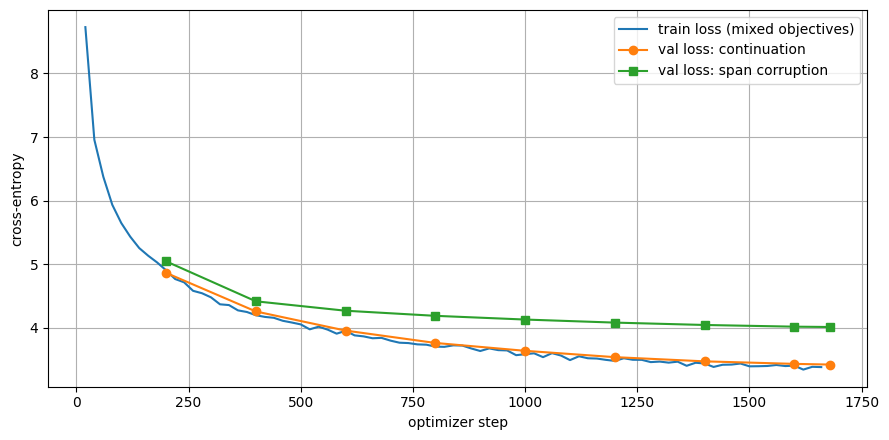

In [13]:
import matplotlib.pyplot as plt
hist = json.load(open(HISTORY_PATH))
tr = [(h["step"], h["train_loss"]) for h in hist if "train_loss" in h]
va = [(h["step"], h["val_loss"]) for h in hist if "val_loss" in h]
vs = [(h["step"], h["val_span_loss"]) for h in hist if "val_span_loss" in h]
plt.figure(figsize=(9, 4.5))
plt.plot(*zip(*tr), label="train loss (mixed objectives)")
plt.plot(*zip(*va), marker="o", label="val loss: continuation")
if vs: plt.plot(*zip(*vs), marker="s", label="val loss: span corruption")
plt.xlabel("optimizer step"); plt.ylabel("cross-entropy"); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/loss_curve.png", dpi=150); plt.show()

## 10. Generation (batched, KV-cached)
The encoder reads the whole prompt once (right-padded, key-masked); the decoder then generates with a KV-cache and cached cross-attention K/V.
Same decoding controls as attempt 1: temperature, top-p, and a repetition penalty applied to **generated** tokens only (so legal terms from the prompt can still be reused).
EOS and the sentinel ids are banned so every continuation reaches 128 words.

In [14]:
best = torch.load(CKPT_BEST, map_location=device, weights_only=False)
model.load_state_dict(best["model"]); model.eval()
print("loaded best checkpoint from step", best["step"])

@torch.no_grad()
def generate(prompt_ids, max_new=MAX_NEW_TOKENS, temperature=0.3, top_p=0.9, rep_penalty=1.1):
    B, L = len(prompt_ids), max(len(p) for p in prompt_ids)
    enc = torch.full((B, L), EOS_ID, dtype=torch.long)
    valid = torch.zeros(B, L, dtype=torch.bool)
    for i, p in enumerate(prompt_ids):                       # right-padding; positions start at 0 for everyone
        enc[i, :len(p)] = torch.tensor(p); valid[i, :len(p)] = True
    enc, valid = enc.to(device), valid.to(device)
    enc_mask = valid[:, None, None, :]
    seen = torch.zeros(B, MODEL_VOCAB, dtype=torch.bool, device=device)
    tok = torch.full((B, 1), BOS_ID, dtype=torch.long, device=device)
    out = []
    with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
        enc_out = model.encode(enc, enc_mask)                # encoder runs once
        cross = model.cross_kv(enc_out)                      # cross-attention K/V computed once
        caches = [(None, None)] * len(model.dec_blocks)
        for t in range(max_new):
            logits, caches = model.decode_step(tok, t, caches, cross, enc_mask)
            lg = logits[:, -1].float()
            lg[:, EOS_ID] = -float("inf"); lg[:, SENT_BASE:] = -float("inf")    # no EOS, no sentinels, no padding ids
            if rep_penalty != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty), lg)
            if temperature <= 0:
                nxt = lg.argmax(-1)
            else:
                probs = F.softmax(lg / temperature, -1)
                sp, si = probs.sort(-1, descending=True)
                drop = (sp.cumsum(-1) - sp) > top_p
                sp = sp.masked_fill(drop, 0.0)
                nxt = si.gather(1, torch.multinomial(sp / sp.sum(-1, keepdim=True), 1)).squeeze(1)
            out.append(nxt); seen[torch.arange(B, device=device), nxt] = True
            tok = nxt[:, None]
    return torch.stack(out, 1).tolist()

PROMPT_TOKEN_CAP = ENC_MAX                                   # keep the LAST ENC_MAX prompt tokens

def continue_texts(prompts, batch_size=16, **gen_kw):
    """prompts: raw strings -> list of continuations (exactly <=128 words each)."""
    enc = [tokenizer.encode(normalize_text(p, KEEP_NEWLINES))[-PROMPT_TOKEN_CAP:] for p in prompts]
    order = sorted(range(len(enc)), key=lambda i: len(enc[i]))      # similar lengths -> less padding
    results = [None] * len(enc)
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        for i, toks in zip(idx, generate([enc[i] for i in idx], **gen_kw)):
            toks = [t for t in toks if t < tokenizer.vocab_size]
            results[i] = " ".join(tokenizer.decode(toks).split()[:TARGET_WORDS])
    return results

lens = [len(tokenizer.encode(normalize_text(p, KEEP_NEWLINES))) for p in test_prompts_raw[:300]]
print(f"test prompt tokens: median {np.median(lens):.0f}, p99 {np.percentile(lens, 99):.0f}, "
      f"cap {PROMPT_TOKEN_CAP} -> {'OK' if np.percentile(lens, 99) <= PROMPT_TOKEN_CAP else 'RAISE ENC_MAX (prompts get truncated)'}")

loaded best checkpoint from step 1679
test prompt tokens: median 609, p99 712, cap 1024 -> OK


## 11. Local validation and decoding sweep
Held-out *documents* are cut into 512-word prompts and 128-word references, mimicking the test.
**BERTScore F1 (the competition's primary metric)** is computed with the `bert-score` package when available (it downloads an evaluation model, which is
allowed because it is used only for scoring); ROUGE-L is always computed as a cheap secondary check. The decoding setting is selected by BERTScore when available.
**Confirm the final choice with the organisers' evaluation script** (link in the assignment), since its exact BERTScore settings may differ.

In [15]:
def rouge_l_f1(hyp, ref):
    h, r = hyp.split(), ref.split()
    if not h or not r: return 0.0
    prev = [0] * (len(r) + 1)
    for i in range(1, len(h) + 1):
        cur = [0] * (len(r) + 1)
        for j in range(1, len(r) + 1):
            cur[j] = prev[j - 1] + 1 if h[i - 1] == r[j - 1] else max(prev[j], cur[j - 1])
        prev = cur
    l = prev[-1]
    return 0.0 if l == 0 else 2 * (l / len(h)) * (l / len(r)) / ((l / len(h)) + (l / len(r)))

bert_scorer = None
if USE_BERTSCORE and not DEBUG:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bert-score"], check=False)
        from bert_score import BERTScorer
        bert_scorer = BERTScorer(lang="en", device=device)
        print("BERTScore ready")
    except Exception as ex:
        print("BERTScore unavailable, falling back to ROUGE-L:", repr(ex)[:200])

def bertscore_f1(hyps, refs):
    _, _, f = bert_scorer.score(hyps, refs, batch_size=16)
    return float(f.mean())

def build_local_eval(n=96):
    items = []
    for line in open(f"{DATA_DIR}/val.jsonl", encoding="utf-8"):
        w = json.loads(line)["text"].split()
        if len(w) >= PROMPT_WORDS + TARGET_WORDS + 50:
            s = random.Random(len(items)).randint(0, len(w) - PROMPT_WORDS - TARGET_WORDS)
            items.append((" ".join(w[s:s + PROMPT_WORDS]),
                          " ".join(w[s + PROMPT_WORDS:s + PROMPT_WORDS + TARGET_WORDS])))
    random.Random(SEED).shuffle(items)
    return items[:n]

local = build_local_eval()
l_prompts, l_refs = [p for p, _ in local], [r for _, r in local]
DECODING = {
    "greedy_rep1.10": dict(temperature=0.0, rep_penalty=1.10),
    "greedy_rep1.20": dict(temperature=0.0, rep_penalty=1.20),
    "t0.3_p0.9_rep1.10": dict(temperature=0.3, top_p=0.9, rep_penalty=1.10),
    "t0.7_p0.9_rep1.10": dict(temperature=0.7, top_p=0.9, rep_penalty=1.10),
}
scores, rouges = {}, {}
for name, kw in DECODING.items():
    t0 = time.time()
    hyps = continue_texts(l_prompts, **kw)
    rouges[name] = float(np.mean([rouge_l_f1(h, r) for h, r in zip(hyps, l_refs)]))
    scores[name] = bertscore_f1(hyps, l_refs) if bert_scorer is not None else rouges[name]
    print(f"{name:20s} {'BERTScore F1' if bert_scorer is not None else 'ROUGE-L F1'} {scores[name]:.4f} "
          f"| ROUGE-L {rouges[name]:.4f} | {time.time() - t0:.0f}s")
    if name == list(DECODING)[0]:
        print("  sample:", hyps[0][:300])
FINAL_DECODING = max(scores, key=scores.get)
print("selected decoding:", FINAL_DECODING)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.9 MB/s eta 0:00:00


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERTScore ready
greedy_rep1.10       BERTScore F1 0.8045 | ROUGE-L 0.1619 | 26s
  sample: the appellant. The appellant was appointed as a clerk in the Department of Personnel and Training, U.P. on deputation basis. The appellant was appointed as a teacher in the Department of Health Services (E) Department, U.P. and was posted as a teacher in the Department of Health Services (F) Departm
greedy_rep1.20       BERTScore F1 0.8175 | ROUGE-L 0.1657 | 21s
t0.3_p0.9_rep1.10    BERTScore F1 0.8131 | ROUGE-L 0.1674 | 22s
t0.7_p0.9_rep1.10    BERTScore F1 0.8189 | ROUGE-L 0.1716 | 22s
selected decoding: t0.7_p0.9_rep1.10


## 12. Official test inference -> `prediction.json` -> `submission.zip`

In [16]:
test_ids = list(test_data.keys())
t0 = time.time()
final_texts = continue_texts([test_data[i]["text"] for i in test_ids], **DECODING[FINAL_DECODING])
print(f"generated {len(final_texts)} continuations in {(time.time() - t0) / 60:.1f} min")

predictions = {str(i): {"text": t} for i, t in zip(test_ids, final_texts)}
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")        # must sit at the archive root

wc = [len(v["text"].split()) for v in predictions.values()]
assert len(predictions) == len(test_data) and min(wc) > 0
print(f"prediction.json: {len(predictions)} items | words per item: min {min(wc)}, mean {np.mean(wc):.1f}, max {max(wc)}")
print("submission archive:", SUBMISSION_ZIP, "->", zipfile.ZipFile(SUBMISSION_ZIP).namelist())

generated 1000 continuations in 2.8 min
prediction.json: 1000 items | words per item: min 77, mean 127.7, max 128
submission archive: /kaggle/working/cs781_phase1_encdec/submission.zip -> ['prediction.json']


## 13. Experiment record (fill in for the report and viva)

| Run | Architecture | Params | Tokens seen | Cont. val loss | Local BERTScore F1 | Local ROUGE-L | Codabench score | Notes |
|---|---|---|---|---|---|---|---|---|
| Attempt 1 | Decoder-only (RoPE, GQA, SwiGLU) | 121M | ~150M | | | | | |
| **Attempt 2** | **Encoder-decoder (this notebook)** | ~124M | ~150M (about 38% supervised) | | | | | 75% continuation + 25% span corruption |

Note on comparing validation losses: attempt 1 averages the loss over **all** positions (many with little context), while this notebook measures the loss on the **next 256 tokens after an 800-token prompt**, which is the test task. Compare models with BERTScore / ROUGE-L on the same local prompts, or evaluate attempt 1 on the same 800 -> 256 split.

Ablations worth running with this notebook (change one thing at a time): `SPAN_FRAC` in {0, 0.25, 0.5}; `ENC_MIN/ENC_MAX`; encoder/decoder depth split (e.g. 8+4); decoding settings.